# Experimento: ¿importa cómo guardamos los datos?

**Parte 1 – Tipo de archivo:** el mismo dato guardado como **CSV**, **Parquet** y **Delta**.
**Parte 2 – Particionamiento:** Delta **sin particionar** vs **particionado por mes**.

| Opción | Analogía |
|---|---|
| **CSV** | Un cuaderno con todo escrito corrido: para ver una columna hay que leer todo |
| **Parquet** | Un archivador con un cajón por columna, y comprimido |
| **Delta** | El mismo archivador, con una libreta que anota cada cambio |
| **Particionado por mes** | Un archivador con una carpeta por mes: para ver noviembre, abres solo esa carpeta |

**Se mide:** tamaño en disco, número de archivos, tiempo de escritura y tiempo de dos consultas.
**Hipótesis:** Parquet y Delta ocupan menos y responden más rápido que CSV; el particionado ayuda a la consulta de un solo mes.

Cada medición se repite y se usa la **mediana**. Los resultados se obtienen al ejecutar; no están escritos de antemano.

In [0]:
# ============================================
# PASO 1: Configuración
# ============================================
import time, statistics
from datetime import datetime
from pyspark.sql import functions as F
import matplotlib.pyplot as plt

CATALOGO, ESQUEMA = "workspace", "olist_exp"
COPIAS = 20          # los datos se copian para que la prueba sea más grande (≈108 mil filas x 20)
REPETICIONES = 3     # cada consulta se mide varias veces; se usa la mediana
MES_FILTRO = "2017-11"

spark.sql(f"CREATE SCHEMA IF NOT EXISTS {CATALOGO}.{ESQUEMA}")
spark.sql(f"CREATE VOLUME IF NOT EXISTS {CATALOGO}.{ESQUEMA}.formatos")
BASE = f"/Volumes/{CATALOGO}/{ESQUEMA}/formatos"
RUTAS = {
    "CSV":                 f"{BASE}/csv",
    "Parquet":             f"{BASE}/parquet",
    "Delta":               f"{BASE}/delta",
    "Delta_particionado":  f"{BASE}/delta_particionado",
}
T_ORIGEN = f"{CATALOGO}.{ESQUEMA}.origen_formatos"
T_RESULT = f"{CATALOGO}.{ESQUEMA}.resultados_formatos"
CORRIDA  = datetime.now().strftime("%Y%m%d_%H%M%S")

for ruta in RUTAS.values():          # empezar limpio
    dbutils.fs.rm(ruta, True)

In [0]:
# ============================================
# PASO 2: Preparar los datos (se usa gold_ventas, la tabla que consultan los KPIs)
# ============================================
base = spark.table(f"{CATALOGO}.olist_nuevo.gold_ventas").select(
    "order_id", "order_item_id", "product_category_name_english", "seller_id",
    "price", "freight_value", "order_purchase_timestamp")

# Se copian los datos cambiando el order_id para que cada fila siga siendo única
origen = (base.crossJoin(spark.range(COPIAS).withColumnRenamed("id", "copia"))
          .withColumn("order_id", F.concat_ws("_", "order_id", F.col("copia").cast("string")))
          .drop("copia")
          .withColumn("anio_mes", F.date_format("order_purchase_timestamp", "yyyy-MM")))
origen.write.mode("overwrite").saveAsTable(T_ORIGEN)

ESQUEMA_DATOS = spark.table(T_ORIGEN).schema
print("Filas de la prueba:", spark.table(T_ORIGEN).count())

Filas de la prueba: 2172760


In [0]:
# ============================================
# PASO 3: Funciones de medición
# ============================================
def tamano_y_archivos(ruta):
    """Suma el tamaño (MB) y cuenta los archivos de una carpeta."""
    total, n, pendientes = 0, 0, [ruta]
    while pendientes:
        for f in dbutils.fs.ls(pendientes.pop()):
            if f.isDir():
                pendientes.append(f.path)
            else:
                total += f.size
                n += 1
    return round(total / 1024 / 1024, 1), n

def mediana_segundos(consulta):
    """Ejecuta una vez de calentamiento (no cuenta) y luego mide varias veces."""
    consulta()
    tiempos = []
    for _ in range(REPETICIONES):
        t0 = time.time()
        consulta()
        tiempos.append(time.time() - t0)
    return round(statistics.median(tiempos), 2)

def leer(variante):
    ruta = RUTAS[variante]
    if variante == "CSV":
        return spark.read.csv(ruta, header=True, schema=ESQUEMA_DATOS)   # esquema explícito: lectura justa
    if variante == "Parquet":
        return spark.read.parquet(ruta)
    return spark.read.format("delta").load(ruta)

# Las dos consultas que se comparan
def consulta_todo(variante):      # usa solo 2 columnas de 8, pero recorre todas las filas
    return lambda: leer(variante).groupBy("product_category_name_english").agg(F.sum("price")).collect()

def consulta_un_mes(variante):    # filtra un solo mes
    return lambda: leer(variante).filter(F.col("anio_mes") == MES_FILTRO).agg(F.sum("price")).collect()

In [0]:
# ============================================
# PASO 4: Guardar en cada formato y medir
# ============================================
datos = spark.table(T_ORIGEN)
filas = []   # (corrida, variante, metrica, valor)

def guardar(variante):
    ruta, w = RUTAS[variante], datos.write.mode("overwrite")
    t0 = time.time()
    if variante == "CSV":
        w.option("header", True).csv(ruta)
    elif variante == "Parquet":
        w.parquet(ruta)
    elif variante == "Delta":
        w.format("delta").save(ruta)
    else:
        w.format("delta").partitionBy("anio_mes").save(ruta)
    return round(time.time() - t0, 2)

for v in RUTAS:
    seg_escritura = guardar(v)
    mb, n = tamano_y_archivos(RUTAS[v])
    q_todo = mediana_segundos(consulta_todo(v))
    q_mes  = mediana_segundos(consulta_un_mes(v))
    for metrica, valor in [("tamano_MB", mb), ("archivos", n), ("escritura_s", seg_escritura),
                           ("consulta_todo_s", q_todo), ("consulta_un_mes_s", q_mes)]:
        filas.append((CORRIDA, v, metrica, float(valor)))
    print(f"{v:20} | {mb} MB | {n} archivos | escritura {seg_escritura}s | consulta total {q_todo}s | un mes {q_mes}s")

CSV                  | 267.0 MB | 4 archivos | escritura 6.33s | consulta total 1.07s | un mes 1.03s
Parquet              | 79.5 MB | 4 archivos | escritura 2.08s | consulta total 0.73s | un mes 0.71s
Delta                | 79.5 MB | 3 archivos | escritura 2.73s | consulta total 0.53s | un mes 0.52s
Delta_particionado   | 28.1 MB | 25 archivos | escritura 2.6s | consulta total 0.55s | un mes 0.5s


In [0]:
# ============================================
# PASO 5: ¿Todos devuelven el mismo resultado? (si no, no se pueden comparar)
# ============================================
control = {}
for v in RUTAS:
    d = leer(v)
    control[v] = (d.count(), round(d.agg(F.sum("price")).first()[0], 2))
print(control)
assert len(set(control.values())) == 1, "Los formatos devuelven datos distintos: no se pueden comparar"
print("OK: los 4 formatos contienen exactamente los mismos datos")

{'CSV': (2172760, 260910618.0), 'Parquet': (2172760, 260910618.0), 'Delta': (2172760, 260910618.0), 'Delta_particionado': (2172760, 260910618.0)}
OK: los 4 formatos contienen exactamente los mismos datos


In [0]:
# ============================================
# PASO 6: Cuadro de resultados
# ============================================
df = spark.createDataFrame(filas, "corrida string, variante string, metrica string, valor double")
df.write.mode("append").saveAsTable(T_RESULT)      # queda guardado como evidencia

orden = ["CSV", "Parquet", "Delta", "Delta_particionado"]
cuadro = (df.toPandas().pivot(index="variante", columns="metrica", values="valor")
            .loc[orden, ["tamano_MB", "archivos", "escritura_s", "consulta_todo_s", "consulta_un_mes_s"]])

# Cuántas veces mejor que CSV (mayor que 1 = mejor que CSV)
cuadro["tamaño: veces menor que CSV"]   = (cuadro.loc["CSV", "tamano_MB"] / cuadro["tamano_MB"]).round(1)
cuadro["consulta total: veces más rápida"] = (cuadro.loc["CSV", "consulta_todo_s"] / cuadro["consulta_todo_s"]).round(1)
cuadro["consulta un mes: veces más rápida"] = (cuadro.loc["CSV", "consulta_un_mes_s"] / cuadro["consulta_un_mes_s"]).round(1)
display(cuadro.reset_index())

variante,tamano_MB,archivos,escritura_s,consulta_todo_s,consulta_un_mes_s,tamaño: veces menor que CSV,consulta total: veces más rápida,consulta un mes: veces más rápida
CSV,267.0,4.0,6.33,1.07,1.03,1.0,1.0,1.0
Parquet,79.5,4.0,2.08,0.73,0.71,3.4,1.5,1.5
Delta,79.5,3.0,2.73,0.53,0.52,3.4,2.0,2.0
Delta_particionado,28.1,25.0,2.6,0.55,0.5,9.5,1.9,2.1


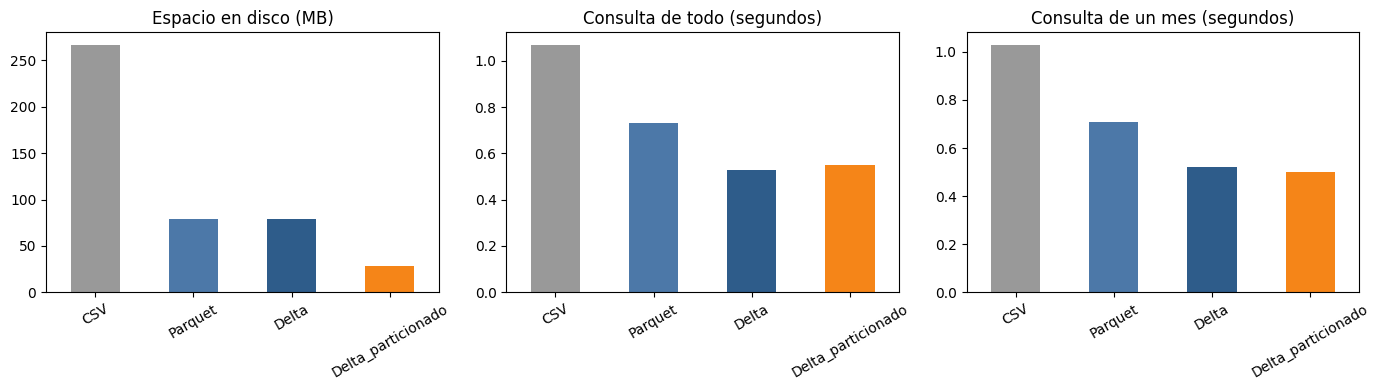

In [0]:
# ============================================
# PASO 7: Gráficos 
# ============================================
fig, ejes = plt.subplots(1, 3, figsize=(14, 4))
for eje, col, titulo in zip(ejes,
        ["tamano_MB", "consulta_todo_s", "consulta_un_mes_s"],
        ["Espacio en disco (MB)", "Consulta de todo (segundos)", "Consulta de un mes (segundos)"]):
    cuadro[col].plot(kind="bar", ax=eje, color=["#999999", "#4c78a8", "#2e5c8a", "#f58518"])
    eje.set_title(titulo); eje.set_xlabel(""); eje.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()